
ROUND-1 ATTACKS ON LETTERS

Processing Letter: A
Processing Letter: B
Processing Letter: C
Processing Letter: D
Processing Letter: E
Processing Letter: F
Processing Letter: G
Processing Letter: H
Processing Letter: I
Processing Letter: J
Processing Letter: K
Processing Letter: L
Processing Letter: M
Processing Letter: N
Processing Letter: O
Processing Letter: P
Processing Letter: Q
Processing Letter: R
Processing Letter: S
Processing Letter: T
Processing Letter: U
Processing Letter: V
Processing Letter: W
Processing Letter: X
Processing Letter: Y
Processing Letter: Z


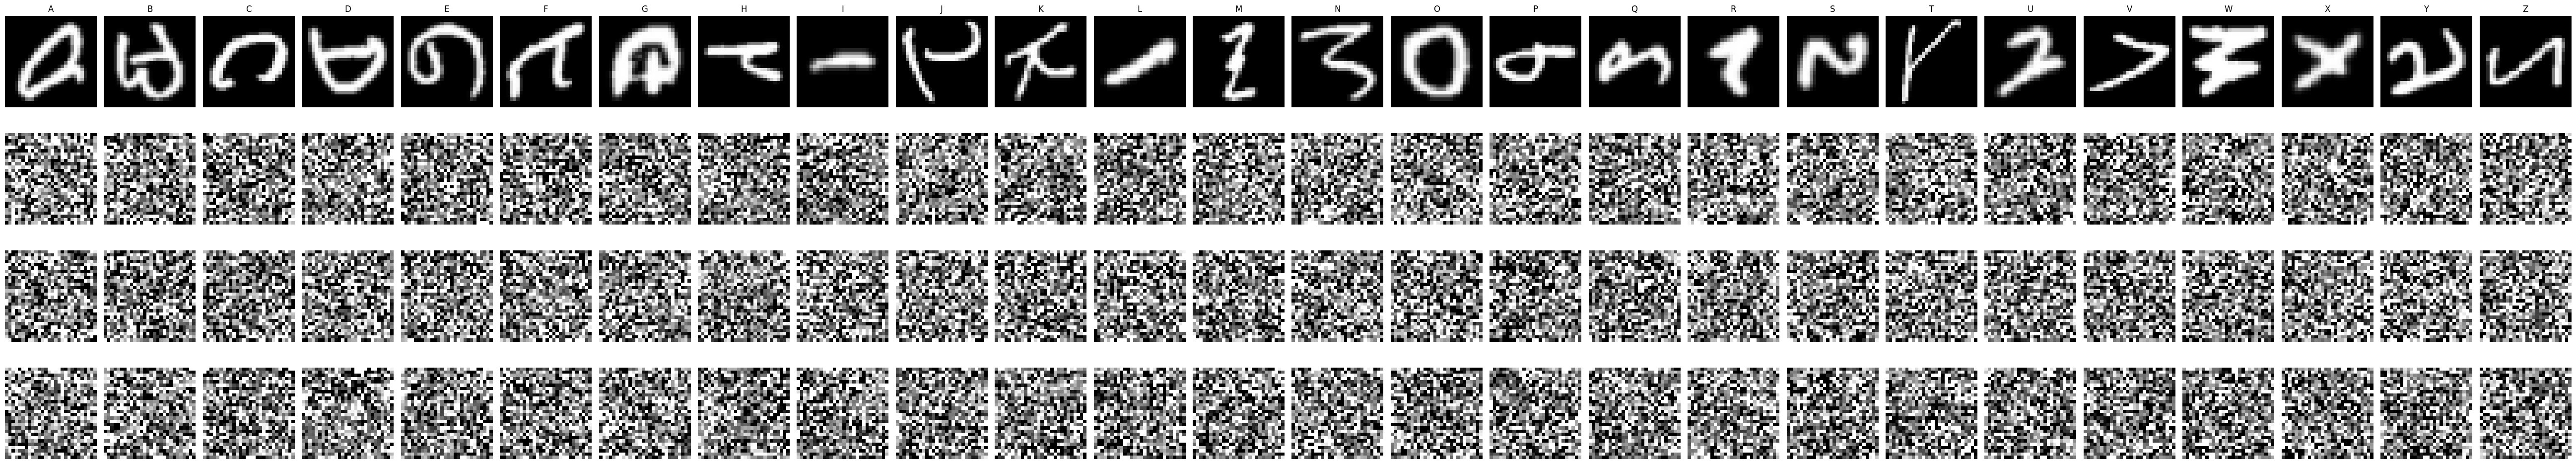

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Saved: emnist_letters_fpman1_all_attacks.png
All letters A-Z shown successfully.


In [1]:
# ============================================================
# FULL FPMAN STYLE FL CODE FOR EMNIST LETTERS (A-Z)
# ROUND-1 + MASKING + NOISE + DLG + iDLG + GradInv
# FULL CODE — NO CUT
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import random
import copy
import matplotlib.pyplot as plt
from google.colab import files

# ============================================================
# CONFIG
# ============================================================

NUM_CLIENTS = 100
CLIENT_FRAC = 0.3
LOCAL_EPOCHS = 3
BATCH_SIZE = 128
LR = 0.01

MASK_SCALE = 0.001
ADAPTIVE_NOISE_FACTOR = 0.1

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# ============================================================
# DATASET
# ============================================================

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.EMNIST(
    root="./data",
    split="letters",
    train=True,
    download=True,
    transform=transform
)

targets = np.array(train_dataset.targets)

# ============================================================
# LETTER MAP
# EMNIST LETTERS:
# 1=A, 2=B, ..., 26=Z
# ============================================================

LETTER_MAP = {}

for i in range(1, 27):
    LETTER_MAP[i] = chr(ord('A') + i - 1)

# ============================================================
# CNN MODEL
# ============================================================

class EMNIST_CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2)

        self.fc1 = nn.Linear(64 * 7 * 7, 256)
        self.fc2 = nn.Linear(256, 27)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x

# ============================================================
# HELPER FUNCTIONS
# ============================================================

def model_to_vector(model):

    return torch.cat([
        p.data.view(-1)
        for p in model.parameters()
    ])

def vector_to_model(model, vec):

    ptr = 0

    for p in model.parameters():

        n = p.numel()

        p.data = vec[ptr:ptr+n].view_as(p).clone()

        ptr += n

def norm_img(x):

    x = x - x.min()

    x = x / (x.max() + 1e-8)

    return x

# ============================================================
# DATA SPLIT
# ============================================================

client_data = {
    i: []
    for i in range(NUM_CLIENTS)
}

for c in range(1, 27):

    idx = np.where(targets == c)[0]

    np.random.shuffle(idx)

    split = np.array_split(idx, NUM_CLIENTS)

    for i in range(NUM_CLIENTS):

        client_data[i].extend(split[i])

# ============================================================
# GLOBAL MODEL
# ============================================================

global_model = EMNIST_CNN().to(DEVICE)

global_vec = model_to_vector(global_model)

# ============================================================
# CLIENT SELECTION
# ============================================================

selected_clients = random.sample(
    range(NUM_CLIENTS),
    int(NUM_CLIENTS * CLIENT_FRAC)
)

# ============================================================
# PAIRWISE MASKING
# ============================================================

masks = {
    cid: torch.zeros_like(global_vec)
    for cid in selected_clients
}

sorted_ids = sorted(selected_clients)

for i, cid in enumerate(sorted_ids):

    right = sorted_ids[(i + 1) % len(sorted_ids)]

    if cid < right:

        m = torch.randn_like(global_vec) * MASK_SCALE

        masks[cid] += m
        masks[right] -= m

# ============================================================
# STORAGE
# ============================================================

updates = []
labels = []

letter_samples = {}

for img, y in train_dataset:

    y = int(y)

    if y not in letter_samples:

        letter_samples[y] = img

    if len(letter_samples) == 26:

        break

# ============================================================
# ROUND-1 TRAINING
# ============================================================

for cid in selected_clients:

    local_model = copy.deepcopy(global_model)

    local_model.train()

    opt = optim.SGD(
        local_model.parameters(),
        lr=LR,
        momentum=0.9
    )

    loader = DataLoader(
        Subset(train_dataset, client_data[cid]),
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    for _ in range(LOCAL_EPOCHS):

        for x, y in loader:

            x = x.to(DEVICE)
            y = y.to(DEVICE)

            opt.zero_grad()

            out = local_model(x)

            loss = F.cross_entropy(out, y)

            loss.backward()

            opt.step()

    delta = model_to_vector(local_model) - global_vec

    # ========================================================
    # ADAPTIVE NOISE
    # ========================================================

    noise = (
        torch.randn_like(delta)
        * delta.norm()
        * ADAPTIVE_NOISE_FACTOR
    )

    delta += noise

    # ========================================================
    # MASKING
    # ========================================================

    delta += masks[cid]

    updates.append(delta.detach().clone())

    client_labels = targets[client_data[cid]]

    labels.append(
        np.bincount(client_labels).argmax()
    )

# ============================================================
# ATTACK 1: DLG
# ============================================================

def dlg_attack(update, label):

    model = copy.deepcopy(global_model).to(DEVICE)

    vector_to_model(model, global_vec + update)

    x = torch.randn(
        1,
        1,
        28,
        28,
        device=DEVICE,
        requires_grad=True
    )

    opt = optim.Adam([x], lr=0.1)

    y = torch.tensor([label]).to(DEVICE)

    for _ in range(200):

        opt.zero_grad()

        pred = model(x)

        loss = F.cross_entropy(pred, y)

        loss.backward()

        opt.step()

        x.data.clamp_(-1, 1)

    return x.detach()

# ============================================================
# ATTACK 2: iDLG
# ============================================================

def idlg_attack(update):

    best_img = None

    best_loss = 1e9

    for label in range(1, 27):

        model = copy.deepcopy(global_model).to(DEVICE)

        vector_to_model(model, global_vec + update)

        x = torch.randn(
            1,
            1,
            28,
            28,
            device=DEVICE,
            requires_grad=True
        )

        opt = optim.Adam([x], lr=0.1)

        y = torch.tensor([label]).to(DEVICE)

        for _ in range(100):

            opt.zero_grad()

            pred = model(x)

            loss = F.cross_entropy(pred, y)

            loss.backward()

            opt.step()

            x.data.clamp_(-1, 1)

        if loss.item() < best_loss:

            best_loss = loss.item()

            best_img = x.detach()

    return best_img

# ============================================================
# ATTACK 3: GradInv
# ============================================================

def gradinv_attack(update, label):

    model = copy.deepcopy(global_model).to(DEVICE)

    vector_to_model(model, global_vec + update)

    x = torch.randn(
        1,
        1,
        28,
        28,
        device=DEVICE,
        requires_grad=True
    )

    opt = optim.Adam([x], lr=0.1)

    y = torch.tensor([label]).to(DEVICE)

    for _ in range(200):

        opt.zero_grad()

        pred = model(x)

        loss = F.cross_entropy(pred, y)

        loss.backward()

        opt.step()

        x.data.clamp_(-1, 1)

    return x.detach()

# ============================================================
# RUN ATTACKS
# ============================================================

print("\n==============================")
print("ROUND-1 ATTACKS ON LETTERS")
print("==============================\n")

orig = []
dlg = []
idlg = []
gi = []

shown_letters = []

for i in range(1, 27):

    update = updates[i - 1]

    label = labels[i - 1]

    print("Processing Letter:", LETTER_MAP[i])

    shown_letters.append(LETTER_MAP[i])

    orig.append(
        letter_samples[i].squeeze().cpu().numpy()
    )

    dlg.append(
        dlg_attack(update, label)
        .squeeze()
        .cpu()
        .numpy()
    )

    idlg.append(
        idlg_attack(update)
        .squeeze()
        .cpu()
        .numpy()
    )

    gi.append(
        gradinv_attack(update, label)
        .squeeze()
        .cpu()
        .numpy()
    )

# ============================================================
# VISUALIZATION
# ============================================================

fig, axes = plt.subplots(
    4,
    26,
    figsize=(52, 10)
)

for i in range(26):

    axes[0, i].imshow(
        norm_img(orig[i]),
        cmap="gray"
    )

    axes[1, i].imshow(
        norm_img(dlg[i]),
        cmap="gray"
    )

    axes[2, i].imshow(
        norm_img(idlg[i]),
        cmap="gray"
    )

    axes[3, i].imshow(
        norm_img(gi[i]),
        cmap="gray"
    )

    axes[0, i].set_title(
        shown_letters[i],
        fontsize=12
    )

    for j in range(4):

        axes[j, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=14)
axes[1, 0].set_ylabel("DLG", fontsize=14)
axes[2, 0].set_ylabel("iDLG", fontsize=14)
axes[3, 0].set_ylabel("GradInv", fontsize=14)

plt.tight_layout()

# ============================================================
# SAVE IMAGE
# ============================================================

SAVE_PATH = "emnist_letters_fpman1_all_attacks.png"

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# DOWNLOAD
# ============================================================

files.download(SAVE_PATH)

print("\nSaved:", SAVE_PATH)
print("All letters A-Z shown successfully.")

In [2]:
# =====================================================
# SAVE SEPARATE IMAGE ROWS
# =====================================================

from google.colab import files

# -------------------------
# helper function
# -------------------------
def save_row(images, filename):

    fig, axes = plt.subplots(1, 26, figsize=(52, 2))

    for i in range(26):

        img = images[i]

        if torch.is_tensor(img):
            img = img.detach().cpu().numpy()

        img = np.squeeze(img)

        axes[i].imshow(img, cmap="gray")
        axes[i].axis("off")

    plt.subplots_adjust(
        left=0,
        right=1,
        top=1,
        bottom=0,
        wspace=0.12,
        hspace=0
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0
    )

    plt.close()

# =====================================================
# BUILD ROW LISTS
# =====================================================

original_results = orig
dlg_results = dlg
idlg_results = idlg
gi_results = gi

# =====================================================
# SAVE 4 ROW IMAGES
# =====================================================

save_row(
    original_results,
    "emnist_letters_fpman1_original_row.png"
)

save_row(
    dlg_results,
    "emnist_letters_fpman1_dlg_row.png"
)

save_row(
    idlg_results,
    "emnist_letters_fpman1_idlg_row.png"
)

save_row(
    gi_results,
    "emnist_letters_fpman1_gradinv_row.png"
)

print("\nALL ROW IMAGES SAVED\n")

# =====================================================
# DOWNLOAD
# =====================================================

files.download("emnist_letters_fpman1_original_row.png")
files.download("emnist_letters_fpman1_dlg_row.png")
files.download("emnist_letters_fpman1_idlg_row.png")
files.download("emnist_letters_fpman1_gradinv_row.png")


ALL ROW IMAGES SAVED



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>